# Module 4 — Task 2: Customer Lifetime Value

**Business problem (brief, verbatim):**
> NovaFin wants to reduce customer attrition. Management asks: Which customers should relationship managers prioritize for retention?

**Task 2 (brief, verbatim):**
> **Task 2 — Customer Lifetime Value.** Estimate: CLV using the provided customer financial variables.

**Customer lifetime value (CLV)** = what a customer is worth to the bank over the relationship, in ₹.

**What this task does (decision M4-12).** The data already has an `Estimated_CLV` for every customer. Task 2 **estimates it from the financial variables**: it compares regression models to find how CLV is built from income, balances and complaints. That gives:
- a rule the bank can use for any customer, including new ones;
- what drives a customer's value, in ₹;
- what the number does and doesn't include, which matters for Task 3.

**Where this task sits:** churn prediction (Task 1) → **customer lifetime value (this task)** → the four groups and the 1,000 customers to contact (Task 3).

| Step | What it does |
| --- | --- |
| 0 | Setup |
| 1 | Know the CLV |
| 2 | Five models compared over 25 rounds |
| 3 | The CLV rule: the weights, found from the data |
| 4 | What each weight means, and what CLV leaves out |
| 5 | The finance view: where the ₹32.8 crore of value sits |
| 6 | What the results say |
| 7 | Save the outputs |

**Decisions used** (in `docs/decisions.md`): M4-12 how CLV is estimated · M4-14 models, validation and measures.

## 0. Setup
Works locally and in Google Colab. Takes about 1 minute.

In [1]:
import os
import sys
import json
import time
import warnings
from pathlib import Path

# ---- Find the project folder: any folder name works, on your computer or in Google Colab ----
# The project folder is the one holding run_novafin.ipynb and data/.
IN_COLAB = "google.colab" in sys.modules
is_project = lambda p: (p / "run_novafin.ipynb").exists() and (p / "data").is_dir()
places = [p for p in [Path.cwd(), *Path.cwd().parents] if is_project(p)]
if IN_COLAB and not places:                                 # Colab starts outside the project: look in /content, then in Google Drive
    for base in [Path("/content"), Path("/content/drive/MyDrive")]:
        if "drive" in base.parts:
            from google.colab import drive
            drive.mount("/content/drive")                   # asks for access to your Google Drive
        for depth in ["", "*/", "*/*/", "*/*/*/"]:
            places += [f.parent for f in sorted(base.glob(depth + "run_novafin.ipynb")) if is_project(f.parent)]
        if places:
            break
if not places:
    raise FileNotFoundError("Project folder not found: unzip the whole project and keep run_novafin.ipynb, data/ and the module folders together (see HOW_TO_RUN.md).")
PROJECT_ROOT = places[0]

MODULE_DIR = PROJECT_ROOT / "module_04_customer_analytics"
OUT_DIR = MODULE_DIR / "outputs" / "task2"
OUT_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(MODULE_DIR / "helpers"))
warnings.filterwarnings("ignore")
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RepeatedKFold
from sklearn.linear_model import LinearRegression, LassoCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from lightgbm import LGBMRegressor

from m04_data import load_customers, GIVEN_INPUTS
from m04_style import apply_style, SURFACE, INK, INK_2, GRID, BLUE, ORANGE, AQUA, CHURN, STAY
apply_style()
plt.close("all")

SEED = 42
LAKH, CRORE = 1e5, 1e7
CONTACTS = 1_000                 # the brief's executive question
pd.set_option("display.width", 220, "display.max_columns", 30)


def save_table(table: pd.DataFrame, name: str) -> None:
    table.to_csv(OUT_DIR / f"{name}.csv", index=False)


def save_chart(fig, name: str) -> None:
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


print("Outputs go to:", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())

Outputs go to: module_04_customer_analytics/outputs/task2


## 1. Know the CLV

Customers: 5,000;  total CLV ₹32.80 crore
CLV: mean ₹65,602, median ₹54,205, smallest ₹0, largest ₹439,367
Customers with CLV exactly ₹0: 17
Median CLV: churners ₹55,579, stayers ₹54,195


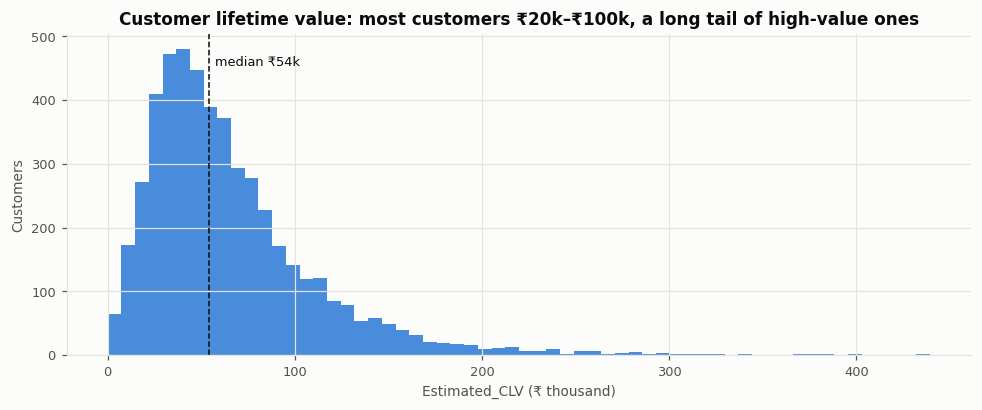

In [2]:
cust = load_customers()
clv = cust.Estimated_CLV.to_numpy()
print(f"Customers: {len(cust):,};  total CLV ₹{clv.sum() / CRORE:.2f} crore")
print(f"CLV: mean ₹{clv.mean():,.0f}, median ₹{np.median(clv):,.0f}, smallest ₹{clv.min():,.0f}, largest ₹{clv.max():,.0f}")
print(f"Customers with CLV exactly ₹0: {(clv == 0).sum()}")
print(f"Median CLV: churners ₹{np.median(clv[cust.Churn_Flag == 1]):,.0f}, stayers ₹{np.median(clv[cust.Churn_Flag == 0]):,.0f}")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(clv / 1000, bins=60, color=BLUE, alpha=0.85)
ax.axvline(np.median(clv) / 1000, color=INK, ls="--", lw=1); ax.text(np.median(clv) / 1000 + 3, ax.get_ylim()[1] * 0.9, f"median ₹{np.median(clv) / 1000:.0f}k", fontsize=8.5)
ax.set_xlabel("Estimated_CLV (₹ thousand)"); ax.set_ylabel("Customers"); ax.set_title("Customer lifetime value: most customers ₹20k–₹100k, a long tail of high-value ones")
fig.tight_layout(); save_chart(fig, "01_clv_distribution"); plt.show()

## 2. Five models compared over 25 rounds (decision M4-14)

Each model predicts `Estimated_CLV` from the 10 financial columns. Predictions are floored at ₹0, since CLV can't be negative.

| Model | What it is |
| --- | --- |
| Linear regression | CLV = a weighted sum of the columns |
| Lasso | The same, with a penalty that can switch columns off (strength chosen by inner 3-fold CV) |
| Decision tree | A flowchart of yes/no questions (depth 8, at least 10 customers per end box) |
| Random forest | 200 trees, averaged (at least 5 customers per end box) |
| LightGBM | 500 small trees built one after another (31 leaves, learning rate 0.05) |

```text
25 rounds: 5,000 customers → 5 parts; train on 4, predict the 5th; × 5 shuffles. Same design as Task 1
RMSE = √(average of (predicted − actual)²)        typical error in ₹; big misses count extra — DECIDES
MAE  = average of |predicted − actual|             plain average error in ₹
R²   = 1 − Σ(predicted − actual)² ÷ Σ(actual − mean)²     share of differences between customers explained
Rank correlation (Spearman) = do the predictions order customers the same way as the actual CLV?
Top-1,000 overlap = of the 1,000 highest-CLV customers, how many the model also puts in its top 1,000
```

**Rule:** the simplest model (earlier in the table) wins unless a more complex one has lower RMSE beyond chance. "Beyond chance": the paired 95% range of the RMSE difference over the 25 rounds excludes 0 (range = mean ± 2.064 × standard deviation ÷ √25; 2.064 is the t-value for 24 degrees of freedom).

In [3]:
X = cust[GIVEN_INPUTS]
MODELS = {"Linear regression": lambda: LinearRegression(),
          "Lasso": lambda: make_pipeline(StandardScaler(), LassoCV(cv=3, random_state=SEED)),
          "Decision tree": lambda: DecisionTreeRegressor(max_depth=8, min_samples_leaf=10, random_state=SEED),
          "Random forest": lambda: RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=4),
          "LightGBM": lambda: LGBMRegressor(n_estimators=500, learning_rate=0.05, num_leaves=31, random_state=SEED, verbose=-1, n_jobs=4)}
SPLITS = list(RepeatedKFold(n_splits=5, n_repeats=5, random_state=SEED).split(X))
top_true = set(np.argsort(-clv)[:CONTACTS])

rows, OOF = [], {}
for name, make in MODELS.items():
    t0 = time.time()
    oof = np.zeros(len(clv))
    for r, (a, b) in enumerate(SPLITS, start=1):
        p = np.maximum(0, make().fit(X.iloc[a], clv[a]).predict(X.iloc[b]))
        oof[b] += p
        rows.append({"Model": name, "Round": r, "RMSE": np.sqrt(mean_squared_error(clv[b], p)), "MAE": mean_absolute_error(clv[b], p),
                     "R2": r2_score(clv[b], p), "Worst error": np.abs(clv[b] - p).max(), "Rank correlation": stats.spearmanr(clv[b], p)[0]})
    OOF[name] = oof / 5
    print(f"{name:<18} {time.time() - t0:4.0f}s", flush=True)
rounds = pd.DataFrame(rows)
comparison = rounds.groupby("Model", sort=False).mean(numeric_only=True).drop(columns="Round")
comparison["Top-1,000 overlap"] = [len(top_true & set(np.argsort(-OOF[m])[:CONTACTS])) for m in comparison.index]

best = comparison.RMSE.idxmin()
d_rows = []
for m in comparison.index:
    d = rounds[rounds.Model == m].RMSE.to_numpy() - rounds[rounds.Model == best].RMSE.to_numpy()
    half = 2.064 * d.std(ddof=1) / np.sqrt(len(d)) if d.std() > 0 else 0.0
    d_rows.append((d.mean(), d.mean() - half, d.mean() + half))
comparison["RMSE vs best"], comparison["95% low"], comparison["95% high"] = zip(*d_rows)
comparison["Within chance of best"] = comparison["95% low"] <= 0
CHOSEN = comparison[comparison["Within chance of best"]].index[0]          # simplest within chance
save_table(comparison.round(4).reset_index(), "model_comparison")
print(f"Lowest RMSE: {best};  chosen (simplest within chance of the best): {CHOSEN}")
comparison.style.format({"RMSE": "₹{:,.0f}", "MAE": "₹{:,.0f}", "R2": "{:.4f}", "Worst error": "₹{:,.0f}", "Rank correlation": "{:.4f}",
                         "RMSE vs best": "₹{:+,.0f}", "95% low": "₹{:+,.0f}", "95% high": "₹{:+,.0f}"})

Linear regression     0s


Lasso                 2s


Decision tree         1s


Random forest        60s


LightGBM             14s


Lowest RMSE: Linear regression;  chosen (simplest within chance of the best): Linear regression


,RMSE,MAE,R2,Worst error,Rank correlation,"Top-1,000 overlap",RMSE vs best,95% low,95% high,Within chance of best
Model,,,,,,,,,,
Linear regression,₹36,₹28,1.0000,₹147,1.0000,1000,₹+0,₹+0,₹+0,True
Lasso,₹88,₹67,1.0000,₹416,1.0000,1000,₹+52,₹+51,₹+53,False
Decision tree,"₹12,057","₹7,826",0.9316,"₹112,636",0.9679,928,"₹+12,020","₹+11,664","₹+12,376",False
Random forest,"₹7,431","₹3,764",0.9738,"₹99,991",0.9933,951,"₹+7,395","₹+6,996","₹+7,794",False
LightGBM,"₹6,739","₹2,152",0.9782,"₹115,113",0.9987,982,"₹+6,702","₹+6,130","₹+7,274",False


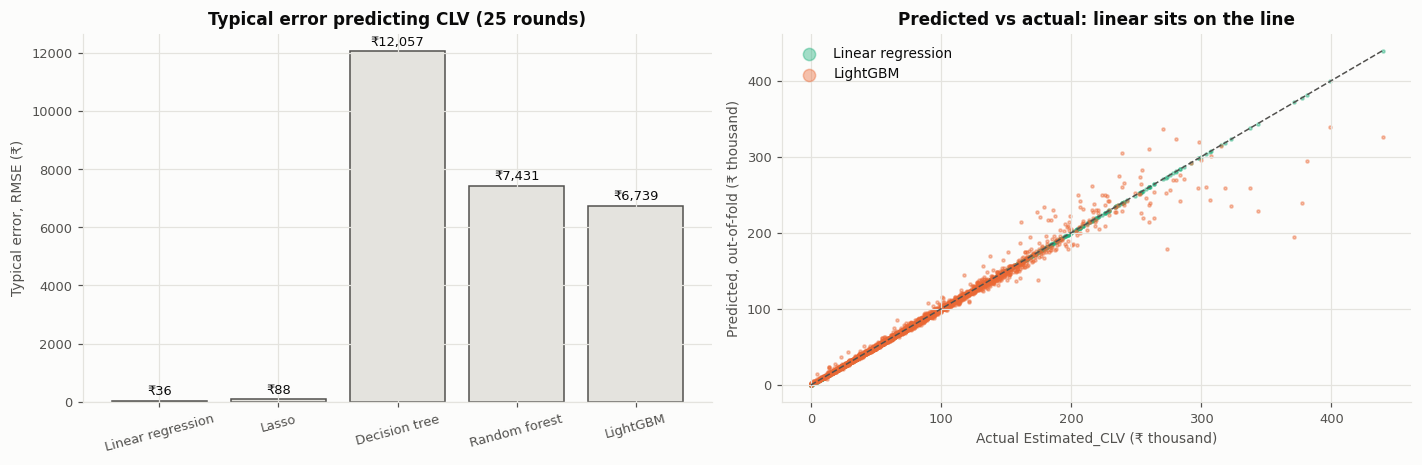

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
x = np.arange(len(comparison))
axes[0].bar(x, comparison.RMSE, color=[AQUA if m == CHOSEN else GRID for m in comparison.index], edgecolor=INK_2)
for i, v in enumerate(comparison.RMSE):
    axes[0].text(i, v + 200, f"₹{v:,.0f}", ha="center", fontsize=8.5)
axes[0].set_xticks(x, comparison.index, fontsize=8.5, rotation=15); axes[0].set_ylabel("Typical error, RMSE (₹)")
axes[0].set_title("Typical error predicting CLV (25 rounds)")
for name, colour in [("Linear regression", AQUA), ("LightGBM", ORANGE)]:
    axes[1].scatter(clv / 1000, OOF[name] / 1000, s=4, alpha=0.4, color=colour, label=name)
lim = clv.max() / 1000
axes[1].plot([0, lim], [0, lim], color=INK_2, ls="--", lw=1)
axes[1].set_xlabel("Actual Estimated_CLV (₹ thousand)"); axes[1].set_ylabel("Predicted, out-of-fold (₹ thousand)")
axes[1].set_title("Predicted vs actual: linear sits on the line"); axes[1].legend(frameon=False, markerscale=4)
fig.tight_layout(); save_chart(fig, "02_model_comparison"); plt.show()

## 3. The CLV rule: the weights, found from the data (decision M4-12)

The chosen model's weights are found by **least squares**: the weights that make the total squared gap between rule and actual CLV as small as possible. Nothing is chosen by us.

Two refinements:
1. **The 17 customers at ₹0** sit where the weighted sum comes out negative, and CLV is floored at ₹0. So the rule is fitted on the 4,983 customers with positive CLV, then floored at ₹0 for everyone.
2. **Lasso's check:** which of the 10 columns does the penalty switch off entirely?

In [5]:
pos = clv > 0
ols = sm.OLS(clv[pos], sm.add_constant(X[pos])).fit()
weights = pd.DataFrame({"Weight": ols.params, "95% low": ols.conf_int()[0], "95% high": ols.conf_int()[1], "p": ols.pvalues})
print(f"Fit on {pos.sum():,} positive-CLV customers: R² = {ols.rsquared:.6f}")
lasso = make_pipeline(StandardScaler(), LassoCV(cv=3, random_state=SEED)).fit(X, clv)
switched_off = [c for c, w in zip(GIVEN_INPUTS, lasso[-1].coef_) if abs(w) < 1e-6]
print("Lasso switches off:", switched_off or "none (all keep small weights)")
weights.style.format({"Weight": "{:,.6f}", "95% low": "{:,.6f}", "95% high": "{:,.6f}", "p": "{:.3g}"})

Fit on 4,983 positive-CLV customers: R² = 1.000000
Lasso switches off: ['Age', 'Products_Held', 'Transactions_Per_Month', 'Digital_Usage', 'Relationship_Length_Years']


,Weight,95% low,95% high,p
const,0.000041,-0.000541,0.000622,0.89
Age,0.000003,-0.000002,0.000008,0.278
Annual_Income,0.040000,0.040000,0.040000,0
Account_Balance,0.030000,0.030000,0.030000,0
Products_Held,-0.000019,-0.000066,0.000027,0.412
Transactions_Per_Month,-0.000007,-0.000026,0.000011,0.449
Digital_Usage,-0.000001,-0.000004,0.000003,0.793
Complaints,"-5,000.000022","-5,000.000087","-4,999.999957",0
Loan_Balance,0.012000,0.012000,0.012000,0
Investment_Balance,0.018000,0.018000,0.018000,0


In [6]:
# The rule with rounded weights, checked against every customer.
RULE = {"Annual_Income": 0.04, "Account_Balance": 0.03, "Loan_Balance": 0.012, "Investment_Balance": 0.018, "Complaints": -5000}
rule_value = np.maximum(0, sum(w * cust[c] for c, w in RULE.items()))
gap = rule_value - clv
print("CLV = max(0,  4% × Annual_Income + 3% × Account_Balance + 1.2% × Loan_Balance + 1.8% × Investment_Balance − ₹5,000 × Complaints)")
print(f"Largest gap between the rule and Estimated_CLV, over all {len(clv):,} customers: ₹{np.abs(gap).max():.4f}")
print(f"Customers differing by more than ₹1: {(np.abs(gap) > 1).sum()};  customers at ₹0 under the rule: {(rule_value == 0).sum()}")
ex = cust.iloc[0]
print(f"\nExample, customer {int(ex.Customer_ID)}: 4% × ₹{ex.Annual_Income:,.0f} + 3% × ₹{ex.Account_Balance:,.0f} + 1.2% × ₹{ex.Loan_Balance:,.0f} "
      f"+ 1.8% × ₹{ex.Investment_Balance:,.0f} − ₹5,000 × {ex.Complaints:.0f} = ₹{rule_value[0]:,.2f} (Estimated_CLV ₹{clv[0]:,.2f})")

CLV = max(0,  4% × Annual_Income + 3% × Account_Balance + 1.2% × Loan_Balance + 1.8% × Investment_Balance − ₹5,000 × Complaints)
Largest gap between the rule and Estimated_CLV, over all 5,000 customers: ₹0.0053
Customers differing by more than ₹1: 0;  customers at ₹0 under the rule: 17

Example, customer 300001: 4% × ₹515,268 + 3% × ₹898,438 + 1.2% × ₹392,907 + 1.8% × ₹1,933,424 − ₹5,000 × 1 = ₹82,080.38 (Estimated_CLV ₹82,080.38)


## 4. What each weight means, and what CLV leaves out

| Weight | Found from the data | In ₹ | A plausible banking reading (our interpretation; the data doesn't document how Estimated_CLV was set) |
| --- | --- | --- | --- |
| Annual_Income | 0.04 | ₹1 lakh of income adds ₹4,000 | Income shows the customer's capacity to bring business: spending, fees, future products |
| Account_Balance | 0.03 | ₹1 lakh in the account adds ₹3,000 | About what a bank earns by lending out deposits (its margin on deposits) |
| Loan_Balance | 0.012 | ₹1 lakh of loan adds ₹1,200 | Interest margin on loans, after the cost of possible defaults |
| Investment_Balance | 0.018 | ₹1 lakh invested adds ₹1,800 | Fees on managed investments |
| Complaints | −5,000 | Each complaint takes away ₹5,000 | The cost of handling an unhappy customer |
| Age, products, transactions, digital usage, relationship length | 0 | No effect | — |

**What CLV leaves out,** and why it matters for Task 3:
- **No churn.** A "lifetime" value would normally fall if a customer is likely to leave. Here it doesn't, which is consistent with Task 1: churn can't be predicted, so it couldn't be priced in anyway.
- **No time horizon or discounting.** It behaves like a yearly value score, not a sum over future years.
- **Relationship length and products don't count,** so a 19-year customer with six products is valued only on income and balances.

## 5. The finance view: where the ₹32.8 crore of value sits

,₹ crore,Share of total before flooring
From income (4%),₹21.16,65%
From account balance (3%),₹6.81,21%
From loans (1.2%),₹2.74,8%
From investments (1.8%),₹5.91,18%
"Complaints (−₹5,000 each)",₹-3.81,-12%


Top customers by CLV,Share of customers,CLV (₹ crore),Share of total CLV,Lowest CLV in the group
100,2%,₹2.51,8%,"₹198,245"
500,10%,₹8.47,26%,"₹122,407"
"1,000",20%,₹13.79,42%,"₹93,019"
"2,500",50%,₹24.45,75%,"₹54,206"


Complaints cost ₹3.81 crore of value across 7,630 complaints


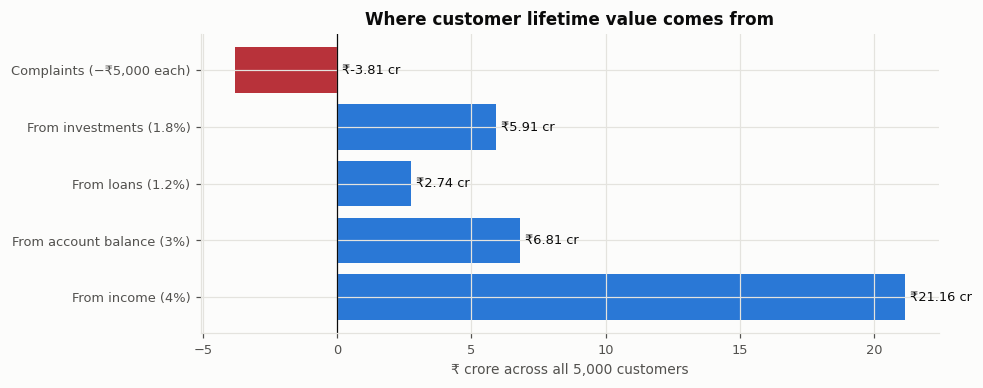

In [7]:
parts = pd.DataFrame({"From income (4%)": 0.04 * cust.Annual_Income, "From account balance (3%)": 0.03 * cust.Account_Balance,
                      "From loans (1.2%)": 0.012 * cust.Loan_Balance, "From investments (1.8%)": 0.018 * cust.Investment_Balance,
                      "Complaints (−₹5,000 each)": -5000 * cust.Complaints})
contrib = (parts.sum() / CRORE).rename("₹ crore").to_frame()
contrib["Share of total before flooring"] = contrib["₹ crore"] / parts.sum(axis=1).clip(lower=None).sum() * CRORE
display(contrib.style.format({"₹ crore": "₹{:,.2f}", "Share of total before flooring": "{:.0%}"}))

order = np.argsort(-clv)
conc = pd.DataFrame([{"Top customers by CLV": f"{n:,}", "Share of customers": n / len(clv), "CLV (₹ crore)": clv[order[:n]].sum() / CRORE,
                      "Share of total CLV": clv[order[:n]].sum() / clv.sum(), "Lowest CLV in the group": clv[order[n - 1]]}
                     for n in [100, 500, 1000, 2500]])
display(conc.style.format({"Share of customers": "{:.0%}", "CLV (₹ crore)": "₹{:,.2f}", "Share of total CLV": "{:.0%}",
                           "Lowest CLV in the group": "₹{:,.0f}"}).hide(axis="index"))
print(f"Complaints cost ₹{-parts['Complaints (−₹5,000 each)'].sum() / CRORE:.2f} crore of value across {int(cust.Complaints.sum()):,} complaints")

fig, ax = plt.subplots(figsize=(9, 3.6))
v = contrib["₹ crore"]
ax.barh(v.index, v.values, color=[BLUE, BLUE, BLUE, BLUE, CHURN])
for i, val in enumerate(v.values):
    ax.text(val + 0.2 if val > 0 else 0.2, i, f"₹{val:,.2f} cr", va="center", ha="left", fontsize=8.5)
ax.axvline(0, color=INK, lw=0.8); ax.set_xlabel("₹ crore across all 5,000 customers")
ax.set_title("Where customer lifetime value comes from")
fig.tight_layout(); save_chart(fig, "03_clv_sources"); plt.show()

## 6. What the results say

### The ML case: which model estimates CLV best (step 2)

| Model | Typical error (RMSE) | Average error | Share explained (R²) | Worst error | Same ranking (rank correlation) | Of the top 1,000 by CLV, also in its top 1,000 |
| --- | --- | --- | --- | --- | --- | --- |
| **Linear regression** | **₹36** | **₹28** | **1.0000** | **₹147** | **1.0000** | **1,000** |
| Lasso | ₹88 | ₹67 | 1.0000 | ₹416 | 1.0000 | 1,000 |
| LightGBM | ₹6,739 | ₹2,152 | 0.978 | ₹1,15,113 | 0.999 | 982 |
| Random forest | ₹7,431 | ₹3,764 | 0.974 | ₹99,991 | 0.993 | 951 |
| Decision tree | ₹12,057 | ₹7,826 | 0.932 | ₹1,12,636 | 0.968 | 928 |

- **Linear regression wins on every measure, beyond chance.** Every other model's RMSE is higher, and the paired 95% range excludes 0.
- **Its typical error of ₹36 is 0.05% of an average CLV of ₹65,602.** The small error comes from the 17 customers whose CLV is floored at ₹0, which a straight line can't reproduce.
- **Tree models do much worse:** typical errors of ₹6,700–₹12,000, and single misses of about ₹1 lakh. Trees build values in steps, which is a poor way to reproduce a rule made of percentages of balances. **The most flexible model isn't the best when the true relationship is simple.**
- **For Task 3, the ranking is what matters:** linear regression puts exactly the same 1,000 customers at the top as the actual CLV. The trees would swap in 18–72 different customers.

### The CLV rule, found from the data (steps 3–4)

```text
CLV = max(0,  4% × Annual_Income + 3% × Account_Balance + 1.2% × Loan_Balance + 1.8% × Investment_Balance − ₹5,000 × Complaints)
```

- **How the weights were found:** least squares, the weights that make the gap between rule and data smallest, fitted on the 4,983 customers with positive CLV. Nothing was chosen by us.
- **How sure we are:** R² = 1.000000. Each weight's 95% range is exact to the fourth decimal (for example 0.040000 to 0.040000). The rule matches `Estimated_CLV` for all 5,000 customers within ₹0.01 (one paisa), including the 17 at ₹0.
- **What doesn't count:**
  - age, products held, transactions, digital usage and relationship length all have weights of zero (p = 0.28–0.79);
  - lasso switches all five off.

**Example (customer 300001):**

```text
4% × ₹5,15,268 + 3% × ₹8,98,438 + 1.2% × ₹3,92,907 + 1.8% × ₹19,33,424 − ₹5,000 × 1 = ₹82,080.38
```

`Estimated_CLV` for this customer is ₹82,080.38.

### The finance case: where the ₹32.80 crore of value sits (step 5)

| Source | ₹ crore | Share |
| --- | --- | --- |
| Income (4%) | ₹21.16 | 65% |
| Account balances (3%) | ₹6.81 | 21% |
| Investments (1.8%) | ₹5.91 | 18% |
| Loans (1.2%) | ₹2.74 | 8% |
| **Complaints (−₹5,000 each, 7,630 complaints)** | **−₹3.81** | **−12%** |

- **Two-thirds of customer value comes from income,** a third from balances held with the bank.
- **Complaints destroy ₹3.81 crore of value,** 12% of the total. That is the one value driver the bank directly controls, and a case for service quality as a retention lever.

| Top customers by CLV | Share of customers | CLV | Share of total CLV | Lowest CLV in the group |
| --- | --- | --- | --- | --- |
| 100 | 2% | ₹2.51 crore | 8% | ₹1,98,245 |
| 500 | 10% | ₹8.47 crore | 26% | ₹1,22,407 |
| **1,000** | **20%** | **₹13.79 crore** | **42%** | **₹93,019** |
| 2,500 | 50% | ₹24.45 crore | 75% | ₹54,206 |

- **Value is concentrated.** The 1,000 most valuable customers (20%) hold **42% of all CLV**: ₹13.79 crore. That is the set the executive question's 1,000 contacts can protect.

### What CLV leaves out (for Task 3)
- **No churn:** a true lifetime value would fall with the chance of leaving. That is consistent with Task 1, where churn can't be predicted, so it couldn't be priced in anyway.
- **No time horizon or discounting:** it behaves like a yearly value score.
- **Loyalty doesn't count:** a 19-year customer with six products is valued only on income and balances.
- **The weights' banking meanings are our interpretation;** the data doesn't document how `Estimated_CLV` was set:
  - 4% of income: the customer's capacity to bring business;
  - 3% of deposits: the margin on deposits;
  - 1.2% of loans: the loan margin after defaults;
  - 1.8% of investments: fees on investments;
  - ₹5,000: the cost of a complaint.

### What goes to Task 3
- `outputs/task2/FINAL_M4_T2_customer_value.csv`: for every customer, `Estimated_CLV`, the CLV from the rule (identical), and the ₹ from each source.
- **For Task 3 to decide:** how to split High / Low CLV, and how to choose 1,000 customers when churn risk is the same for everyone (Task 1).

## 7. Save the outputs

- **`FINAL_M4_T2_customer_value.csv`: the hand-off to Task 3.** For every customer: Estimated_CLV, the CLV from the rule, and the ₹ coming from each source (income, account, loans, investments, complaints).
- **`model_comparison.csv`:** the five models over 25 rounds.
- The charts above and `key_numbers.json`.

In [8]:
out = pd.concat([cust[["Customer_ID", "Estimated_CLV"]], pd.Series(rule_value.round(2), name="CLV_from_rule"),
                 parts.round(2), pd.Series(OOF[CHOSEN].round(2), name="CLV_out_of_fold_estimate")], axis=1)
assert len(out) == 5000 and out.notna().all().all()
save_table(out, "FINAL_M4_T2_customer_value")


def r4(v):
    return round(float(v), 4)


key = {"total_clv_crore": round(float(clv.sum() / CRORE), 2), "chosen": CHOSEN, "best_rmse": best,
       "rmse": {m: round(float(comparison.loc[m, "RMSE"]), 1) for m in comparison.index},
       "rule": RULE, "rule_max_gap": round(float(np.abs(gap).max()), 4), "lasso_switched_off": switched_off,
       "top1000_share_of_clv": r4(conc.loc[conc["Top customers by CLV"] == "1,000", "Share of total CLV"].iloc[0]),
       "complaints_cost_crore": round(float(-parts["Complaints (−₹5,000 each)"].sum() / CRORE), 2)}
(OUT_DIR / "key_numbers.json").write_text(json.dumps(key, indent=1, ensure_ascii=False), encoding="utf-8")
print("Saved to", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())
print(sorted(p.name for p in OUT_DIR.iterdir()))

Saved to module_04_customer_analytics/outputs/task2
['01_clv_distribution.png', '02_model_comparison.png', '03_clv_sources.png', 'FINAL_M4_T2_customer_value.csv', 'key_numbers.json', 'model_comparison.csv']
